In [1]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:

crosstab = pd.crosstab(df["category"], df["isBestSeller"])

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
# Create a crosstab showing the proportion of Best Sellers in each category
proportion_table = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)

proportion_table

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [5]:
# Convert proportions to percentages and round to 2 decimal places
proportion_table = proportion_table * 100

proportion_table.round(2)

isBestSeller,False,True
category,,
3D Printers,99.60,0.40
3D Printing & Scanning,99.95,0.05
Abrasive & Finishing Products,98.00,2.00
Action Cameras,99.94,0.06
Adapters,98.82,1.18
...,...,...
Wind Instruments,97.20,2.80
Window Treatments,97.91,2.09
Women,98.80,1.20


In [6]:
# Sort categories by the proportion of Best Sellers (highest to lowest)
proportion_table.sort_values(by=True, ascending=False)

isBestSeller,False,True
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
...,...,...
Bedding Collections,100.000000,0.000000
CPUs,100.000000,0.000000
"CD, Disc & Tape Players",100.000000,0.000000


In [10]:
# Import the Chi-Square test function
from scipy.stats import chi2_contingency

# Perform the Chi-Square test using the crosstab
chi2, p, dof, expected = chi2_contingency(crosstab)

# Display the p-value
print(f"P-value: {p}")

P-value: 0.0


In [8]:
import sys

print(sys.executable)

C:\Python314\python.exe


In [9]:
from scipy.stats import chi2_contingency

In [11]:
# Import NumPy
import numpy as np

# Calculate the total number of observations
n = crosstab.to_numpy().sum()

# Calculate Cramer's V
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))

print(f"Cramer's V: {cramers_v:.3f}")

Cramer's V: 0.122


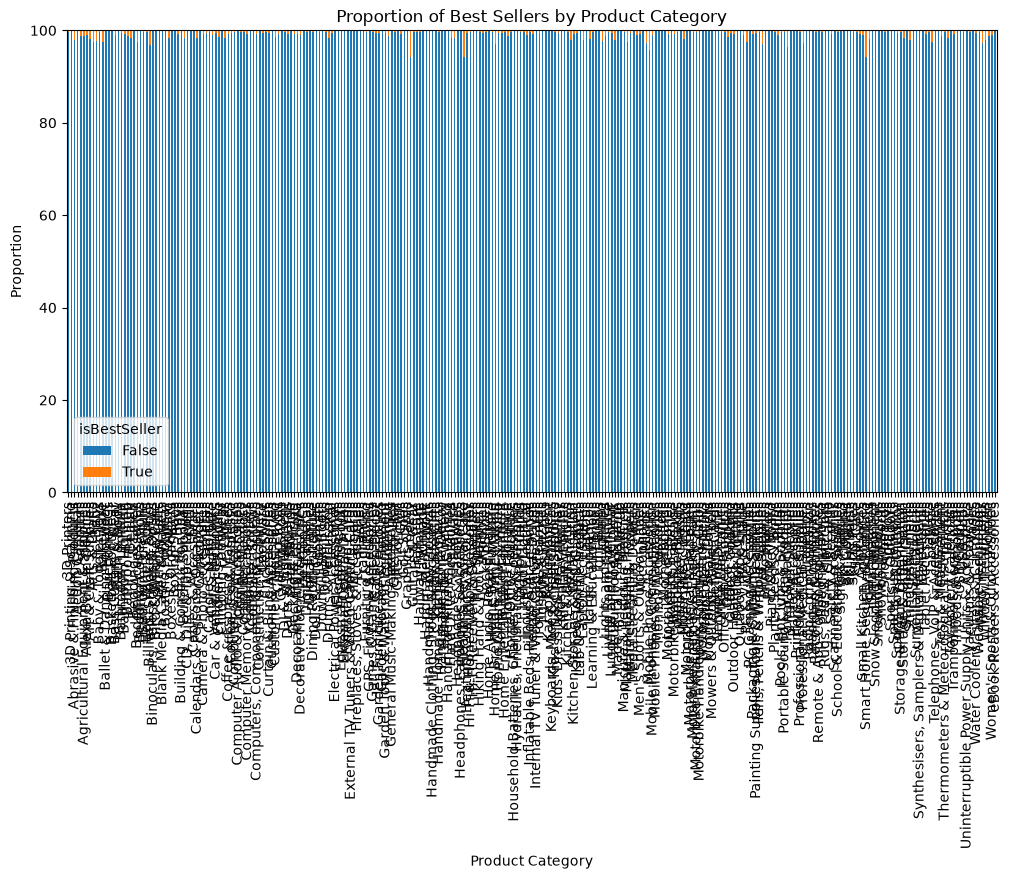

In [14]:
# Import the Matplotlib library for data visualization
import matplotlib.pyplot as plt

# Create a stacked bar chart showing the proportion of Best Sellers by category
proportion_table.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

# Add a title and axis labels
plt.title("Proportion of Best Sellers by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Proportion")

# Display the chart
plt.show()

The dataset contains a very large number of product categories, making the chart difficult to read. In practice, displaying only the most frequent categories would improve readability.

In [15]:
# Calculate the first and third quartiles of the price column
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# Calculate the Interquartile Range (IQR)
IQR = Q3 - Q1

# Define the lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers from the dataset
df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

In [16]:
# Identify the 20 most frequent product categories
top20_categories = df_no_outliers["category"].value_counts().head(20).index

In [17]:
# Keep only products belonging to the top 20 categories
top20_df = df_no_outliers[
    df_no_outliers["category"].isin(top20_categories)
]

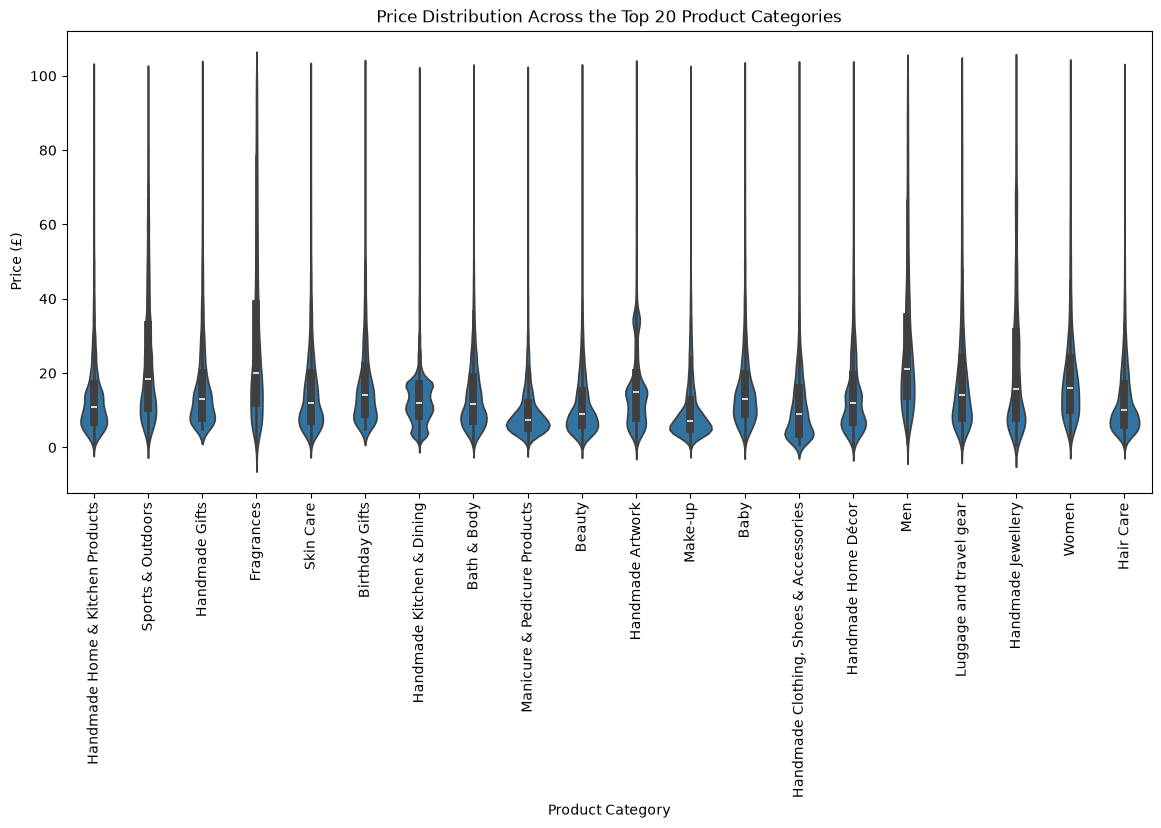

In [18]:
# Import Seaborn for statistical visualizations
import seaborn as sns

# Create a violin plot of product prices for the top 20 categories
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=top20_df,
    x="category",
    y="price"
)

# Improve readability
plt.xticks(rotation=90)
plt.title("Price Distribution Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")

# Display the plot
plt.show()

In [19]:
# Calculate the median price for each product category
median_prices = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

# Display the categories with the highest median prices
median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [20]:
median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [ ]:
#Desktop PCs have the highest median price (£74), followed by Boxing Shoes (£69.79) and Tablets (£69.00).

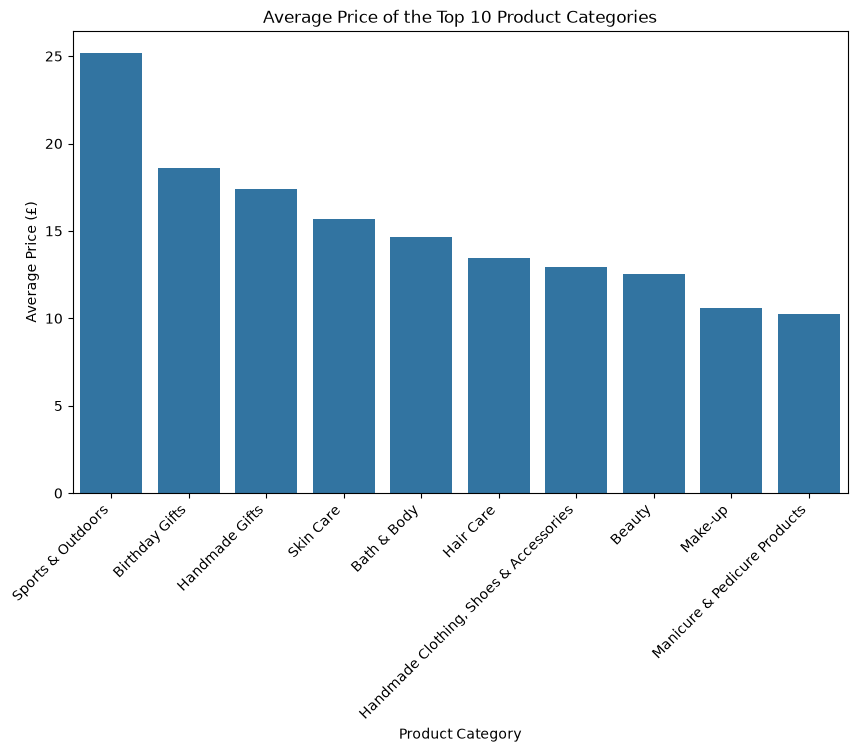

In [24]:
# Identify the 10 most frequent product categories
top10_categories = df_no_outliers["category"].value_counts().head(10).index

# Calculate the average price for the top 10 categories
top10_avg_price = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

# Create a bar chart of the average prices
plt.figure(figsize=(10,6))

sns.barplot(
    data=top10_avg_price.reset_index(),
    x="category",
    y="price"
)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.title("Average Price of the Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")

plt.show()

In [25]:
# Display the average price for the top 10 categories
top10_avg_price

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

Sports & Outdoors has the highest average price among the top 10 most frequent product categories, with an average price of approximately £25.17.

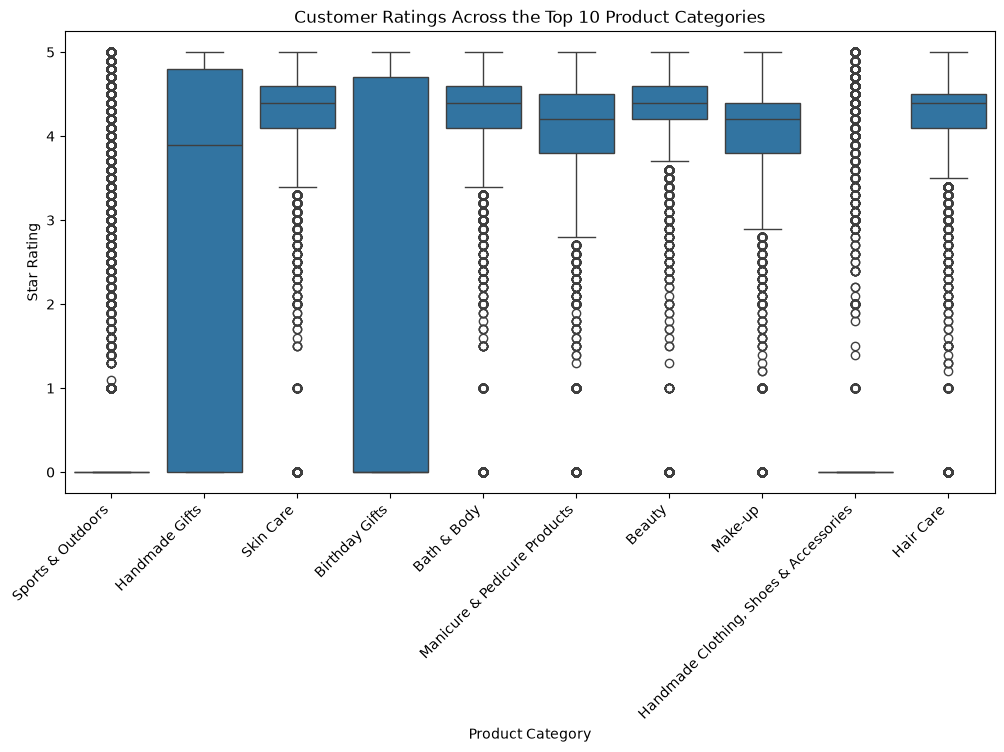

In [26]:
# Create a box plot comparing ratings across the top 10 categories
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top10_categories)],
    x="category",
    y="stars"
)

# Improve readability
plt.xticks(rotation=45, ha="right")
plt.title("Customer Ratings Across the Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Star Rating")

plt.show()

In [27]:
# Calculate the median rating for each of the top 10 categories
median_stars = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_stars

category
Bath & Body                               4.4
Beauty                                    4.4
Hair Care                                 4.4
Skin Care                                 4.4
Make-up                                   4.2
Manicure & Pedicure Products              4.2
Handmade Gifts                            3.9
Birthday Gifts                            0.0
Handmade Clothing, Shoes & Accessories    0.0
Sports & Outdoors                         0.0
Name: stars, dtype: float64

Bath & Body, Beauty, Hair Care, and Skin Care have the highest median customer rating (4.4 stars) among the top 10 product categories.

In [28]:
# Calculate the Pearson correlation coefficient between price and stars
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])

print(correlation)

-0.07767299878181444


The Pearson correlation coefficient is -0.078, indicating a very weak negative correlation between price and customer ratings. This suggests that product price is not strongly related to the number of stars received.

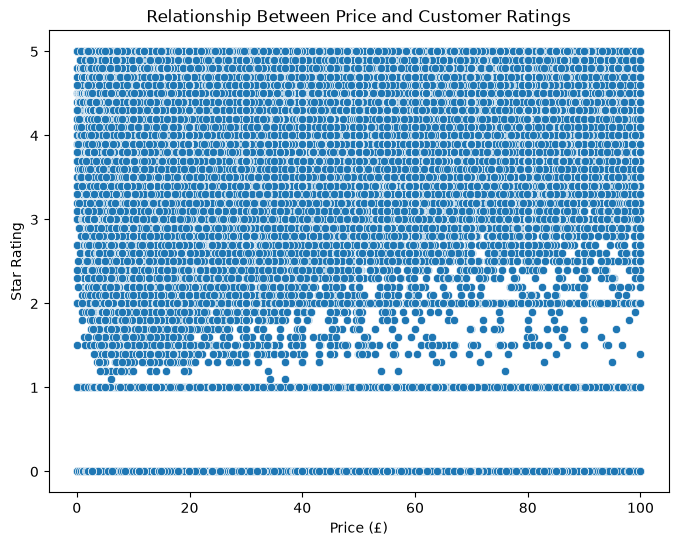

In [29]:
# Create a scatter plot showing the relationship between price and star rating
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_no_outliers,
    x="price",
    y="stars"
)

# Add a title and axis labels
plt.title("Relationship Between Price and Customer Ratings")
plt.xlabel("Price (£)")
plt.ylabel("Star Rating")

plt.show()

The scatter plot shows no clear linear relationship between product price and customer ratings. The points are widely scattered, which is consistent with the very weak negative correlation (-0.078).

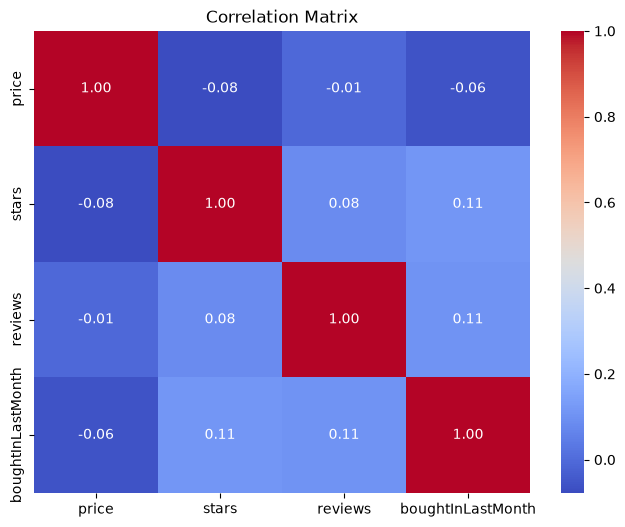

In [30]:
# Compute the correlation matrix for numerical variables
correlation_matrix = df_no_outliers[
    ["price", "stars", "reviews", "boughtInLastMonth"]
].corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add a title
plt.title("Correlation Matrix")

plt.show()

The heatmap confirms that there are no strong correlations between the numerical variables. All correlation coefficients are close to zero, indicating weak linear relationships.

In [32]:
# Import the QQ plot function
import statsmodels.api as sm

# Create a QQ plot for the price variable
sm.qqplot(df_no_outliers["price"], line="45")

plt.title("QQ Plot of Product Prices")

plt.show()

In [ ]:
The QQ plot shows that the price variable does not follow a normal distribution. The points deviate considerably from the reference line, especially in the upper tail.